# Simulation Timing & Optimization Duration Estimate

Times a single forward simulation run for each of the configurations in
the campaign and uses those measurements to estimate total wall-clock time for
all optimization runs.

**Method**
1. For every simulation defined in `campaign..._config.yaml`, build the exact
   same `CellCultureSimulation` object that the campaign script builds.
2. Time `N_REPEATS` consecutive runs with `time.perf_counter()`.
3. For each optimization config, read the number of optimized parameters,
   compute `population_size = n_params × min(5×n_params, 50)`, and set
   `maxiter = 50` (non-performance-mode default).
4. Total evaluations per run: `N_evals = population_size × (maxiter + 1)`.
5. Estimated optimization wall-time (accounting for parallel workers):
$$T_{opt} = \frac{N_{evals} \times \bar{t}_{sim}}{N_{workers}}$$
6. Grand total across all simulations:
$$T_{total} = \sum_{i=1}^{N_{scripts}} \frac{N_{evals,i} \times \bar{t}_{sim,i}}{N_{workers}}$$

> **Note** The campaign scripts run `performance_mode=False` (default), so
> timings are taken in that mode to match the actual optimization workload.

## 1 · Import Required Libraries

In [1]:
import time
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# ── AnimaKinetica imports ──────────────────────────────────────────────────────
from animakinetica.core.simulation        import CellCultureSimulation
from animakinetica.core.parameters        import SimulationParameters
from animakinetica.models.kinetics        import Kinetics
from animakinetica.models.odesystems      import OperatingMode
from animakinetica.models.feed_strategies import FeedStrategy
from animakinetica.models.perfusion_strategies import PerfusionStrategy
from animakinetica.models.gas_controllers  import GasController

print("✓ Imports successful")

✓ Imports successful


## 2 · Define Simulation Configurations

In [2]:
CAMPAIGN_DIR   = Path(".").resolve()                # absolute path so param files resolve correctly
PARAMS_DIR     = CAMPAIGN_DIR / "parameters"
OPT_CONFIG_DIR = CAMPAIGN_DIR / "optimization_config"

# ── Load campaign YAML ─────────────────────────────────────────────────────────
with open(CAMPAIGN_DIR / "campaign_config.yaml") as f:
    campaign_cfg = yaml.safe_load(f)

opt_settings = campaign_cfg["optimization_settings"]
WORKERS       = opt_settings["workers"]          # From campaign_config
MAXITER_FULL  = 50    # non-performance-mode default (performance_mode=False)
POPSIZE_SCALE = 5     # scipy differential_evolution rule of thumb

print(f"Campaign dir                   : {CAMPAIGN_DIR}")
print(f"Workers (parallel evaluations) : {WORKERS}")
print(f"maxiter (non-performance-mode) : {MAXITER_FULL}")
print(f"popsize multiplier             : {POPSIZE_SCALE} × n_params  (capped at 50)")
print(f"\nSimulations defined in campaign_config.yaml:")
for s in campaign_cfg["simulations"]:
    print(f"  {s['id']:35s}  opt_config={s.get('opt_config','—')}")


Campaign dir                   : C:\Users\btumulero\OneDrive - Delft University of Technology\2. Code\Operational Mode Screening\Campaign_1_fixed_stoichiometry_Humbird
Workers (parallel evaluations) : 4
maxiter (non-performance-mode) : 50
popsize multiplier             : 5 × n_params  (capped at 50)

Simulations defined in campaign_config.yaml:
  fedbatch_constant                    opt_config=F_C
  fedbatch_linear                      opt_config=F_L
  fedbatch_exponential                 opt_config=F_E
  fedbatch_csfr                        opt_config=F_CSFR
  fedbatch_gsp                         opt_config=F_GSP
  batch                                opt_config=BSF
  chemostat                            opt_config=C
  cf_constant                          opt_config=CF_C
  cf_tbs                               opt_config=CF_TBS
  cf_tbp                               opt_config=CF_TBP
  cf_cspr                              opt_config=CF_CSPR
  cf_gsp                               opt_co

In [3]:
def count_opt_params(opt_config_key: str) -> int:
    """Count the number of parameters in an optimization config YAML."""
    path = OPT_CONFIG_DIR / f"{opt_config_key}_optimization.yaml"
    if not path.exists():
        return 0
    with open(path) as f:
        cfg = yaml.safe_load(f)
    count = 0
    for section, params in cfg.items():
        if isinstance(params, dict):
            count += len(params)
    return count


def build_sim_configs(campaign_cfg: dict) -> list[dict]:
    """Build a list of fully-resolved simulation config dicts.

    Merges three layers (later wins):
      1. simulation_defaults  – kinetics, solver_method, base parameter_sets
      2. mode_defaults[mode]  – mode-specific parameter_sets (appended),
         default feed/perfusion strategies
      3. per-simulation overrides – feed_strategy, perfusion_strategy, etc.
    """
    defaults   = campaign_cfg.get("simulation_defaults", {})
    mode_defs  = campaign_cfg.get("mode_defaults", {})

    configs = []
    for s in campaign_cfg["simulations"]:
        # ── Layer 1: simulation_defaults ───────────────────────────────────
        merged = dict(defaults)
        solver_method = s.get("solver_method") or merged.get("solver_method")

        # ── Layer 2: mode_defaults ─────────────────────────────────────────
        mode = s["mode"]
        if mode in mode_defs:
            for key, val in mode_defs[mode].items():
                if val is None:
                    continue  # null = "keep whatever layer 1 provided"
                if key == "parameter_sets":
                    # Append mode-specific params to the base list
                    base_params = list(merged.get("parameter_sets") or [])
                    merged["parameter_sets"] = base_params + list(val)
                else:
                    merged[key] = val

        # ── Layer 3: per-simulation overrides ──────────────────────────────
        for key, val in s.items():
            if key in ("id", "label", "opt_config"):
                continue  # metadata, not a simulation setting
            if val is not None:
                merged[key] = val

        # ── Resolve parameter file paths ───────────────────────────────────
        param_sets  = merged.get("parameter_sets") or []
        param_files = [PARAMS_DIR / Path(p).with_suffix(".yaml")
                       for p in param_sets]

        # ── Optimization sizing ────────────────────────────────────────────
        n_params = count_opt_params(s["opt_config"]) if s.get("opt_config") else 0
        pop_size  = int(np.minimum(POPSIZE_SCALE * n_params, 50)) * n_params
        n_evals   = pop_size * (MAXITER_FULL + 1)

        configs.append({
            "id"                : s["id"],
            "label"             : s["label"],
            "mode"              : OperatingMode[s["mode"]],
            "solver_method"     : solver_method,
            "kinetics"          : Kinetics[merged.get("kinetics", "EXCESS")],
            "feed_strategy"     : FeedStrategy[merged["feed_strategy"]]           if merged.get("feed_strategy")      else None,
            "perfusion_strategy": PerfusionStrategy[merged["perfusion_strategy"]] if merged.get("perfusion_strategy") else None,
            "param_files"       : [str(p) for p in param_files],
            "opt_config"        : s.get("opt_config", ""),
            "n_opt_params"      : n_params,
            "pop_size"          : pop_size,
            "n_evals"           : n_evals,
        })
    return configs


sim_configs = build_sim_configs(campaign_cfg)

print(f"{'ID':35s}  {'n_params':>8}  {'pop_size':>9}  {'n_evals':>9}  {'solver_method':<15}")
print("-" * 85)
for c in sim_configs:
    print(f"{c['id']:35s}  {c['n_opt_params']:>8d}  {c['pop_size']:>9d}  {c['n_evals']:>9d}  {c['solver_method']:<15}")
print(f"\nTotal function evaluations across all optimizations: {sum(c['n_evals'] for c in sim_configs):,}")

ID                                   n_params   pop_size    n_evals  solver_method  
-------------------------------------------------------------------------------------
fedbatch_constant                          10        500      25500  LSODA          
fedbatch_linear                            11        550      28050  LSODA          
fedbatch_exponential                       11        550      28050  LSODA          
fedbatch_csfr                              10        500      25500  LSODA          
fedbatch_gsp                               10        500      25500  LSODA          
batch                                      10        500      25500  LSODA          
chemostat                                  10        500      25500  LSODA          
cf_constant                                11        550      28050  LSODA          
cf_tbs                                     13        650      33150  LSODA          
cf_tbp                                     13        650      33

## 3 · Run and Time Individual Simulations

Each simulation is run `N_REPEATS` times and wall-clock time is measured with
`time.perf_counter()`.  
**`performance_mode=False`** — matches the actual campaign script setup so the
timings reflect the true per-evaluation cost during optimization.

> ⚠️ This cell takes a few minutes to execute depending on your hardware.

In [4]:
N_REPEATS = 1       # number of timing repeats per simulation for a stable estimate
USE_PERFORMANCE_MODE = False  # False = matches campaign scripts (performance_mode=False)

# Cache loaded parameters to avoid reloading YAML files for identical parameter sets
_param_cache: dict[tuple, SimulationParameters] = {}

def get_params(param_files: list[str]) -> SimulationParameters:
    key = tuple(param_files)
    if key not in _param_cache:
        _param_cache[key] = SimulationParameters.load_parameters(param_files)
    return _param_cache[key]


def time_simulation(cfg: dict, n_repeats: int = N_REPEATS) -> dict:
    """Run one simulation n_repeats times and return timing statistics."""
    times = []
    error = None
    params = get_params(cfg["param_files"])

    for _ in range(n_repeats):
        try:
            sim = CellCultureSimulation(
                parameters        = params,
                kinetics          = cfg["kinetics"],
                operating_mode    = cfg["mode"],
                feed_strategy     = cfg["feed_strategy"],
                perfusion_strategy= cfg["perfusion_strategy"],
                gas_controller    = GasController.CASCADE_N_FG_XO2,
                performance_mode  = USE_PERFORMANCE_MODE,
                solver_method     = cfg["solver_method"]
            )
            t0 = time.perf_counter()
            sim.run_simulation()
            t1 = time.perf_counter()
            times.append(t1 - t0)
        except Exception as e:
            error = str(e)
            break

    if times:
        return {
            "id"          : cfg["id"],
            "label"       : cfg["label"],
            "mode"        : cfg["mode"].name,
            "n_opt_params": cfg["n_opt_params"],
            "pop_size"    : cfg["pop_size"],
            "n_evals"     : cfg["n_evals"],
            "min_s"       : min(times),
            "max_s"       : max(times),
            "mean_s"      : sum(times) / len(times),
            "n_repeats"   : len(times),
            "error"       : "",
        }
    else:
        return {
            "id"          : cfg["id"],
            "label"       : cfg["label"],
            "mode"        : cfg["mode"].name,
            "n_opt_params": cfg["n_opt_params"],
            "pop_size"    : cfg["pop_size"],
            "n_evals"     : cfg["n_evals"],
            "min_s"       : float("nan"),
            "max_s"       : float("nan"),
            "mean_s"      : float("nan"),
            "n_repeats"   : 0,
            "error"       : error or "unknown",
        }


# ── Run timing loop ────────────────────────────────────────────────────────────
timing_rows = []
total_sims  = len(sim_configs)
print(f"Timing {total_sims} simulations × {N_REPEATS} repeats "
      f"(performance_mode={USE_PERFORMANCE_MODE}) …\n")

wall_start = time.perf_counter()
for i, cfg in enumerate(sim_configs, 1):
    print(f"[{i:2d}/{total_sims}] {cfg['id']} … ", end="", flush=True)
    row = time_simulation(cfg)
    timing_rows.append(row)
    if row["error"]:
        print(f"ERROR: {row['error']}")
    else:
        print(f"mean={row['mean_s']:.3f}s  min={row['min_s']:.3f}s  max={row['max_s']:.3f}s")

wall_elapsed = time.perf_counter() - wall_start
print(f"\n✓ All timing runs completed in {wall_elapsed:.1f} s")

df_timing = pd.DataFrame(timing_rows)
df_timing

Timing 17 simulations × 1 repeats (performance_mode=False) …

[ 1/17] fedbatch_constant … Loading parameters from 5 file(s) sequentially...
  [1/5] Base: C:\Users\btumulero\OneDrive - Delft University of Technology\2. Code\Operational Mode Screening\Campaign_1_fixed_stoichiometry_Humbird\parameters\base_parameters.yaml
  [2/5] Updating with: C:\Users\btumulero\OneDrive - Delft University of Technology\2. Code\Operational Mode Screening\Campaign_1_fixed_stoichiometry_Humbird\parameters\stoichiometry\anab_Humbird_cell.yaml
  [3/5] Updating with: C:\Users\btumulero\OneDrive - Delft University of Technology\2. Code\Operational Mode Screening\Campaign_1_fixed_stoichiometry_Humbird\parameters\stoichiometry\cata_Humbird_wildtype_yield_based.yaml
  [4/5] Updating with: C:\Users\btumulero\OneDrive - Delft University of Technology\2. Code\Operational Mode Screening\Campaign_1_fixed_stoichiometry_Humbird\parameters\cell_properties\cell_Humbird.yaml
  [5/5] Updating with: C:\Users\btumulero\OneDri

,id,label,mode,n_opt_params,pop_size,n_evals,min_s,max_s,mean_s,n_repeats,error
0,fedbatch_constant,Fed-Batch | Humbird Wildtype | Constant Feed,FEDBATCH,10,500,25500,0.073210,0.073210,0.073210,1,
1,fedbatch_linear,Fed-Batch | Humbird Wildtype | Linear Feed,FEDBATCH,11,550,28050,0.093820,0.093820,0.093820,1,
2,fedbatch_exponential,Fed-Batch | Humbird Wildtype | Exponential Feed,FEDBATCH,11,550,28050,0.058080,0.058080,0.058080,1,
3,fedbatch_csfr,Fed-Batch | Humbird Wildtype | Cell-Specific F...,FEDBATCH,10,500,25500,0.108039,0.108039,0.108039,1,
4,fedbatch_gsp,Fed-Batch | Humbird Wildtype | Glucose Setpoin...,FEDBATCH,10,500,25500,1.601961,1.601961,1.601961,1,
5,batch,Batch | Humbird Wildtype,BATCH_WITH_STARTUP_FEDBATCH,10,500,25500,0.120722,0.120722,0.120722,1,
6,chemostat,Chemostat | Humbird Wildtype | Constant Feed,CHEMOSTAT,10,500,25500,0.213054,0.213054,0.213054,1,
7,cf_constant,Concentrated Fed-Batch | Humbird Wildtype | Co...,CONCENTRATED_FEDBATCH,11,550,28050,0.183174,0.183174,0.183174,1,
8,cf_tbs,Concentrated Fed-Batch | Humbird Wildtype | To...,CONCENTRATED_FEDBATCH,13,650,33150,0.518751,0.518751,0.518751,1,
9,cf_tbp,Concentrated Fed-Batch | Humbird Wildtype | To...,CONCENTRATED_FEDBATCH,13,650,33150,0.728107,0.728107,0.728107,1,


## 4 · Aggregate Timing Results & Compute Optimization Statistics

For each optimization run, the differential evolution algorithm (non-performance-mode settings):
- `maxiter = 50`
- `popsize = min(5 × n_params, 50)`  →  `population_size = n_params × popsize`
- `N_evals = population_size × (maxiter + 1)`

Estimated wall-time per optimization (with `workers` parallel evaluations):
$$T_{opt,i} = \frac{N_{evals,i} \times \bar{t}_{sim,i}}{N_{workers}}$$

In [5]:
# ── Compute per-simulation optimization time estimate ─────────────────────────
df = df_timing.copy()
df["t_opt_sequential_s"] = df["n_evals"] * df["mean_s"]           # no parallelism
df["t_opt_parallel_s"]   = df["t_opt_sequential_s"] / WORKERS     # with workers
df["t_opt_min"]          = df["t_opt_parallel_s"] / 60
df["t_opt_h"]            = df["t_opt_min"]         / 60

# ── Pretty display ─────────────────────────────────────────────────────────────
display_cols = [
    "id", "mode", "n_opt_params", "pop_size", "n_evals",
    "mean_s", "t_opt_min", "t_opt_h",
]
df_display = df[display_cols].copy()
df_display.columns = [
    "Simulation ID", "Mode", "# Params", "Pop Size", "Total Evals",
    "t_sim mean (s)", "T_opt (min)", "T_opt (h)",
]

pd.set_option("display.float_format", "{:.2f}".format)
df_display.style \
    .format({
        "t_sim mean (s)" : "{:.3f}",
        "T_opt (min)"    : "{:.1f}",
        "T_opt (h)"      : "{:.2f}",
    }) \
    .background_gradient(subset=["T_opt (h)"], cmap="YlOrRd")

,Simulation ID,Mode,# Params,Pop Size,Total Evals,t_sim mean (s),T_opt (min),T_opt (h)
0,fedbatch_constant,FEDBATCH,10,500,25500,0.073,7.8,0.13
1,fedbatch_linear,FEDBATCH,11,550,28050,0.094,11.0,0.18
2,fedbatch_exponential,FEDBATCH,11,550,28050,0.058,6.8,0.11
3,fedbatch_csfr,FEDBATCH,10,500,25500,0.108,11.5,0.19
4,fedbatch_gsp,FEDBATCH,10,500,25500,1.602,170.2,2.84
5,batch,BATCH_WITH_STARTUP_FEDBATCH,10,500,25500,0.121,12.8,0.21
6,chemostat,CHEMOSTAT,10,500,25500,0.213,22.6,0.38
7,cf_constant,CONCENTRATED_FEDBATCH,11,550,28050,0.183,21.4,0.36
8,cf_tbs,CONCENTRATED_FEDBATCH,13,650,33150,0.519,71.7,1.19
9,cf_tbp,CONCENTRATED_FEDBATCH,13,650,33150,0.728,100.6,1.68


## 5 · Estimate Total Optimization Campaign Time

$$T_{total} = \sum_{i=1}^{N_{scripts}} \frac{N_{evals,i} \times \bar{t}_{sim,i}}{N_{workers}}$$

In [6]:
# ── Grand totals ───────────────────────────────────────────────────────────────
total_evals_all    = df["n_evals"].sum()
total_opt_s        = df["t_opt_parallel_s"].sum()
total_opt_min      = total_opt_s  / 60
total_opt_h        = total_opt_min / 60

# Per-mode breakdown
mode_summary = (
    df.groupby("mode")[["n_evals", "t_opt_sequential_s", "t_opt_parallel_s"]]
    .sum()
    .assign(t_opt_min=lambda d: d["t_opt_parallel_s"] / 60,
            t_opt_h  =lambda d: d["t_opt_parallel_s"] / 3600)
    .reset_index()
    .rename(columns={
        "mode"               : "Operating Mode",
        "n_evals"            : "Total Evals",
        "t_opt_sequential_s" : "Sequential (s)",
        "t_opt_parallel_s"   : f"Parallel / {WORKERS} workers (s)",
        "t_opt_min"          : f"Parallel (min)",
        "t_opt_h"            : f"Parallel (h)",
    })
)
print("Per-mode optimization time breakdown:")
print(mode_summary.to_string(index=False, float_format="{:.2f}".format))
print()
print("─" * 60)
print(f"  Total function evaluations : {total_evals_all:>12,.0f}")
print(f"  Total opt time (seq)       : {total_opt_s/3600:>10.2f} h  ({total_opt_s/60:.0f} min)")
print(f"  Total opt time ({WORKERS} workers) : {total_opt_h:>10.2f} h  ({total_opt_min:.0f} min)")
print("─" * 60)
print()
# Assumptions reminder
print("Assumptions:")
print(f"  • performance_mode     = {USE_PERFORMANCE_MODE}  →  maxiter={MAXITER_FULL}, popsize_scale={POPSIZE_SCALE}×n_params (cap 50)")
print(f"  • Workers              = {WORKERS}")
print(f"  • N_evals per run      = pop_size × (maxiter + 1) = n_params × min({POPSIZE_SCALE}n, 50) × {MAXITER_FULL+1}")
print(f"  • Parallel efficiency  = 100 %  (ideal, no overhead)")
print(f"  • t_sim used           = mean of {N_REPEATS} repeats")

Per-mode optimization time breakdown:
             Operating Mode  Total Evals  Sequential (s)  Parallel / 4 workers (s)  Parallel (min)  Parallel (h)
BATCH_WITH_STARTUP_FEDBATCH        25500         3078.41                    769.60           12.83          0.21
                  CHEMOSTAT        25500         5432.87                   1358.22           22.64          0.38
      CONCENTRATED_FEDBATCH       150450       202941.51                  50735.38          845.59         14.09
       CONTINUOUS_PERFUSION       150450       339858.66                  84964.67         1416.08         23.60
                   FEDBATCH       132600        49732.62                  12433.16          207.22          3.45

────────────────────────────────────────────────────────────
  Total function evaluations :      484,500
  Total opt time (seq)       :      41.74 h  (2504 min)
  Total opt time (4 workers) :      41.74 h  (2504 min)
────────────────────────────────────────────────────────────

Assu

## 6 · Visualize Timing Results

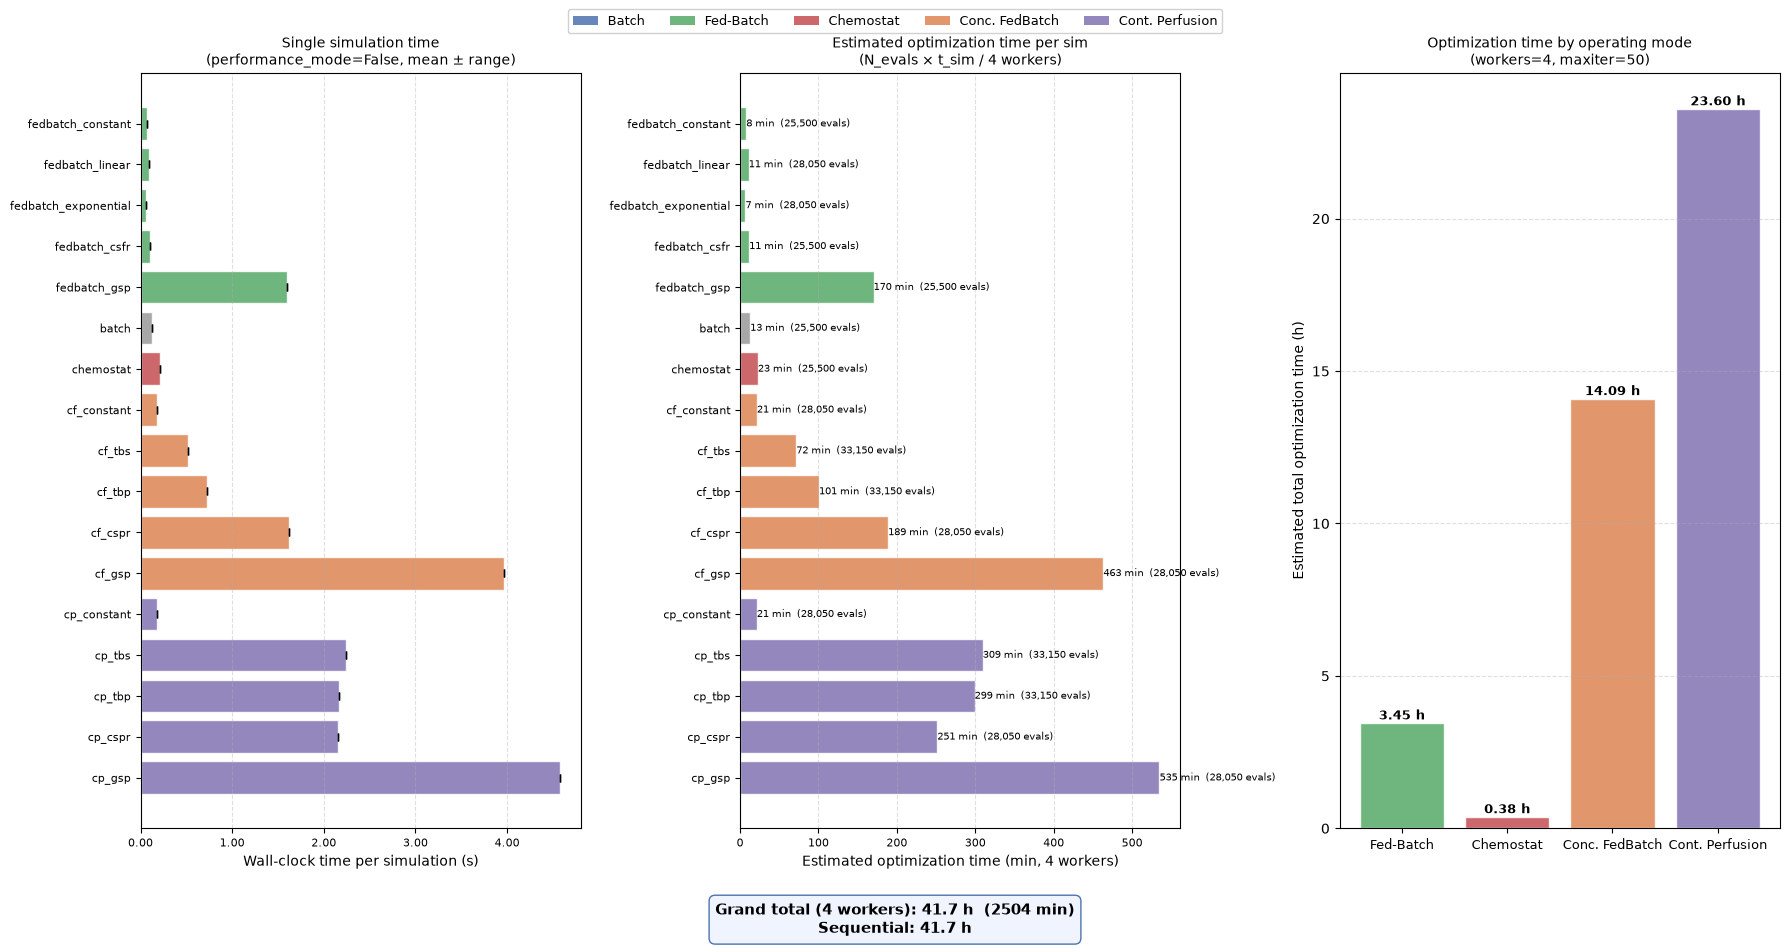

In [7]:
MODE_COLORS = {
    "BATCH"                : "#4C72B0",
    "FEDBATCH"             : "#55A868",
    "CHEMOSTAT"            : "#C44E52",
    "CONCENTRATED_FEDBATCH": "#DD8452",
    "CONTINUOUS_PERFUSION" : "#8172B2",
}

fig, axes = plt.subplots(1, 3, figsize=(18, max(6, len(df) * 0.42 + 1.5)))

# ── Chart 1: Mean single-simulation time ──────────────────────────────────────
ax1 = axes[0]
colors  = [MODE_COLORS.get(m, "#999999") for m in df["mode"]]
y_pos   = range(len(df))
ax1.barh(list(y_pos), df["mean_s"], xerr=[df["mean_s"] - df["min_s"],
                                           df["max_s"]  - df["mean_s"]],
         color=colors, alpha=0.85, edgecolor="white", capsize=3)
ax1.set_yticks(list(y_pos))
ax1.set_yticklabels(df["id"], fontsize=8)
ax1.invert_yaxis()
ax1.set_xlabel("Wall-clock time per simulation (s)")
ax1.set_title("Single simulation time\n(performance_mode=False, mean ± range)", fontsize=10)
ax1.xaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
ax1.tick_params(axis="x", labelsize=8)
ax1.grid(axis="x", linestyle="--", alpha=0.4)

# ── Chart 2: Estimated optimization time per simulation ───────────────────────
ax2 = axes[1]
ax2.barh(list(y_pos), df["t_opt_min"], color=colors, alpha=0.85, edgecolor="white")
ax2.set_yticks(list(y_pos))
ax2.set_yticklabels(df["id"], fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel(f"Estimated optimization time (min, {WORKERS} workers)")
ax2.set_title(f"Estimated optimization time per sim\n"
              f"(N_evals × t_sim / {WORKERS} workers)", fontsize=10)
ax2.tick_params(axis="x", labelsize=8)
ax2.grid(axis="x", linestyle="--", alpha=0.4)
# Add value labels
for i, (t, ne) in enumerate(zip(df["t_opt_min"], df["n_evals"])):
    if not np.isnan(t):
        ax2.text(t + 0.1, i, f"{t:.0f} min  ({ne:,} evals)", va="center", fontsize=7)

# ── Chart 3: Stacked bar by operating mode ────────────────────────────────────
ax3 = axes[2]
mode_order = ["BATCH", "FEDBATCH", "CHEMOSTAT", "CONCENTRATED_FEDBATCH", "CONTINUOUS_PERFUSION"]
mode_labels_short = {
    "BATCH"                : "Batch",
    "FEDBATCH"             : "Fed-Batch",
    "CHEMOSTAT"            : "Chemostat",
    "CONCENTRATED_FEDBATCH": "Conc. FedBatch",
    "CONTINUOUS_PERFUSION" : "Cont. Perfusion",
}
mode_totals = (
    df.groupby("mode")["t_opt_h"]
    .sum()
    .reindex(mode_order)
    .dropna()
)
bar_colors = [MODE_COLORS.get(m, "#999999") for m in mode_totals.index]
bars = ax3.bar(
    [mode_labels_short[m] for m in mode_totals.index],
    mode_totals.values,
    color=bar_colors,
    edgecolor="white",
    alpha=0.85,
)
ax3.set_ylabel("Estimated total optimization time (h)")
ax3.set_title(f"Optimization time by operating mode\n"
              f"(workers={WORKERS}, maxiter={MAXITER_FULL})", fontsize=10)
ax3.tick_params(axis="x", labelsize=9)
ax3.grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width() / 2, h + 0.02,
             f"{h:.2f} h", ha="center", va="bottom", fontsize=9, fontweight="bold")

# ── Grand-total annotation ─────────────────────────────────────────────────────
total_label = (
    f"Grand total ({WORKERS} workers): {total_opt_h:.1f} h  ({total_opt_min:.0f} min)\n"
    f"Sequential: {total_opt_s/3600:.1f} h"
)
fig.text(0.5, -0.02, total_label, ha="center", va="top", fontsize=11,
         fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="#f0f4ff", edgecolor="#4C72B0"))

# ── Legend ─────────────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=mode_labels_short[m], alpha=0.85)
                   for m, c in MODE_COLORS.items()]
fig.legend(handles=legend_elements, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 1.02), fontsize=9, framealpha=0.9)

plt.tight_layout()
# plt.savefig(CAMPAIGN_DIR / "simulation_timing.png", dpi=150, bbox_inches="tight")
# print("✓ Figure saved to simulation_timing.png")
plt.show()


In [8]:
# ── Export timing results to CSV for reference ─────────────────────────────────
# csv_path = CAMPAIGN_DIR / "simulation_timing_results.csv"
# df.to_csv(csv_path, index=False, float_format="%.6f")
# print(f"✓ Timing results saved to {csv_path.name}")

# ── Print final summary table ─────────────────────────────────────────────────
print("\n" + "=" * 80)
print(f"  CAMPAIGN 3 OPTIMIZATION DURATION ESTIMATE  (workers={WORKERS})")
print("=" * 80)
print(f"  {'Simulation ID':40s}  {'t_sim (s)':>9}  {'N_evals':>9}  {'T_opt (min)':>11}  {'T_opt (h)':>9}")
print("-" * 80)
for _, row in df.iterrows():
    t_sim   = row["mean_s"]
    t_opt_m = row["t_opt_min"]
    t_opt_h = row["t_opt_h"]
    n_evals = int(row["n_evals"])
    print(f"  {row['id']:40s}  {t_sim:9.3f}  {n_evals:9,d}  {t_opt_m:11.1f}  {t_opt_h:9.2f}")
print("─" * 80)
print(f"  {'TOTAL':40s}  {'':>9}  {int(total_evals_all):9,d}  {total_opt_min:11.0f}  {total_opt_h:9.2f}")
print("=" * 80)


  CAMPAIGN 3 OPTIMIZATION DURATION ESTIMATE  (workers=4)
  Simulation ID                             t_sim (s)    N_evals  T_opt (min)  T_opt (h)
--------------------------------------------------------------------------------
  fedbatch_constant                             0.073     25,500          7.8       0.13
  fedbatch_linear                               0.094     28,050         11.0       0.18
  fedbatch_exponential                          0.058     28,050          6.8       0.11
  fedbatch_csfr                                 0.108     25,500         11.5       0.19
  fedbatch_gsp                                  1.602     25,500        170.2       2.84
  batch                                         0.121     25,500         12.8       0.21
  chemostat                                     0.213     25,500         22.6       0.38
  cf_constant                                   0.183     28,050         21.4       0.36
  cf_tbs                                        0.519     33